<a href="https://colab.research.google.com/github/uzmaa29/deeplearning/blob/main/MnistDigit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 building neural networks from scratch and hyperparameter exploration & mnist digit classification:


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

np.random.seed(42)

In [ ]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training data shape:", X_train.shape)
print("Testing data shape :", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape : (10000, 28, 28)


In [ ]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

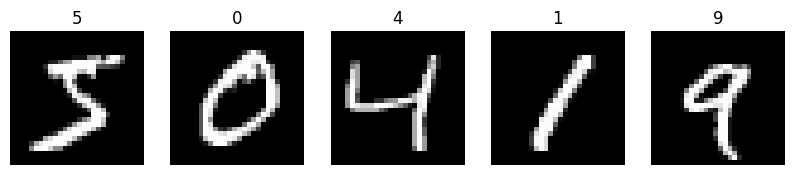

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for i in range(5):
    axes[i].imshow(X_train[i].reshape(28, 28), cmap="gray")
    axes[i].set_title(np.argmax(y_train[i]))
    axes[i].axis("off")

plt.show()

In [ ]:
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

def cross_entropy_loss(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-10, 1 - 1e-10)
    return -np.mean(np.sum(y_true * np.log(y_pred), axis=1))

In [ ]:
class NeuralNetwork:
    def __init__(
        self,
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=0.001,
        activation="relu",
        optimizer="adam"
    ):
        self.learning_rate = learning_rate
        self.activation_name = activation
        self.optimizer_name = optimizer

        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
        self.b2 = np.zeros((1, output_size))

        self.initialize_optimizer()

    def activation(self, x):
        if self.activation_name == "relu":
            return relu(x)
        elif self.activation_name == "sigmoid":
            return sigmoid(x)

    def activation_derivative(self, x):
        if self.activation_name == "relu":
            return relu_derivative(x)
        elif self.activation_name == "sigmoid":
            return sigmoid_derivative(x)

    def initialize_optimizer(self):
        self.vW1 = np.zeros_like(self.W1)
        self.vb1 = np.zeros_like(self.b1)
        self.vW2 = np.zeros_like(self.W2)
        self.vb2 = np.zeros_like(self.b2)

        self.sW1 = np.zeros_like(self.W1)
        self.sb1 = np.zeros_like(self.b1)
        self.sW2 = np.zeros_like(self.W2)
        self.sb2 = np.zeros_like(self.b2)

        self.mW1 = np.zeros_like(self.W1)
        self.mb1 = np.zeros_like(self.b1)
        self.mW2 = np.zeros_like(self.W2)
        self.mb2 = np.zeros_like(self.b2)

        self.t = 0

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self.activation(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = softmax(self.Z2)
        return self.A2

    def backward(self, X, y):
        m = X.shape[0]

        dZ2 = self.A2 - y
        dW2 = np.dot(self.A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * self.activation_derivative(self.Z1)
        dW1 = np.dot(X.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        return dW1, db1, dW2, db2

    def update_weights(self, dW1, db1, dW2, db2):
        if self.optimizer_name == "sgd":
            self.W1 -= self.learning_rate * dW1
            self.b1 -= self.learning_rate * db1
            self.W2 -= self.learning_rate * dW2
            self.b2 -= self.learning_rate * db2

        elif self.optimizer_name == "momentum":
            beta = 0.9

            self.vW1 = beta * self.vW1 + (1 - beta) * dW1
            self.vb1 = beta * self.vb1 + (1 - beta) * db1
            self.vW2 = beta * self.vW2 + (1 - beta) * dW2
            self.vb2 = beta * self.vb2 + (1 - beta) * db2

            self.W1 -= self.learning_rate * self.vW1
            self.b1 -= self.learning_rate * self.vb1
            self.W2 -= self.learning_rate * self.vW2
            self.b2 -= self.learning_rate * self.vb2

        elif self.optimizer_name == "rmsprop":
            beta = 0.9
            epsilon = 1e-8

            self.sW1 = beta * self.sW1 + (1 - beta) * dW1**2
            self.sb1 = beta * self.sb1 + (1 - beta) * db1**2
            self.sW2 = beta * self.sW2 + (1 - beta) * dW2**2
            self.sb2 = beta * self.sb2 + (1 - beta) * db2**2

            self.W1 -= self.learning_rate * dW1 / (np.sqrt(self.sW1) + epsilon)
            self.b1 -= self.learning_rate * db1 / (np.sqrt(self.sb1) + epsilon)
            self.W2 -= self.learning_rate * dW2 / (np.sqrt(self.sW2) + epsilon)
            self.b2 -= self.learning_rate * db2 / (np.sqrt(self.sb2) + epsilon)

        elif self.optimizer_name == "adam":
            beta1 = 0.9
            beta2 = 0.999
            epsilon = 1e-8

            self.t += 1

            self.mW1 = beta1 * self.mW1 + (1 - beta1) * dW1
            self.mb1 = beta1 * self.mb1 + (1 - beta1) * db1
            self.mW2 = beta1 * self.mW2 + (1 - beta1) * dW2
            self.mb2 = beta1 * self.mb2 + (1 - beta1) * db2

            self.sW1 = beta2 * self.sW1 + (1 - beta2) * dW1**2
            self.sb1 = beta2 * self.sb1 + (1 - beta2) * db1**2
            self.sW2 = beta2 * self.sW2 + (1 - beta2) * dW2**2
            self.sb2 = beta2 * self.sb2 + (1 - beta2) * db2**2

            mW1_hat = self.mW1 / (1 - beta1**self.t)
            mb1_hat = self.mb1 / (1 - beta1**self.t)
            mW2_hat = self.mW2 / (1 - beta1**self.t)
            mb2_hat = self.mb2 / (1 - beta1**self.t)

            sW1_hat = self.sW1 / (1 - beta2**self.t)
            sb1_hat = self.sb1 / (1 - beta2**self.t)
            sW2_hat = self.sW2 / (1 - beta2**self.t)
            sb2_hat = self.sb2 / (1 - beta2**self.t)

            self.W1 -= self.learning_rate * mW1_hat / (np.sqrt(sW1_hat) + epsilon)
            self.b1 -= self.learning_rate * mb1_hat / (np.sqrt(sb1_hat) + epsilon)
            self.W2 -= self.learning_rate * mW2_hat / (np.sqrt(sW2_hat) + epsilon)
            self.b2 -= self.learning_rate * mb2_hat / (np.sqrt(sb2_hat) + epsilon)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

    def accuracy(self, X, y):
        predictions = self.predict(X)
        actual = np.argmax(y, axis=1)
        return np.mean(predictions == actual)

    def train(self, X, y, epochs=10, batch_size=32):
        history = {"loss": [], "accuracy": []}
        n_samples = X.shape[0]

        for epoch in range(epochs):
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_loss = 0
            batches = 0

            for start in range(0, n_samples, batch_size):
                end = start + batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                predictions = self.forward(X_batch)
                loss = cross_entropy_loss(y_batch, predictions)

                dW1, db1, dW2, db2 = self.backward(X_batch, y_batch)
                self.update_weights(dW1, db1, dW2, db2)

                epoch_loss += loss
                batches += 1

            epoch_loss /= batches
            accuracy = self.accuracy(X, y)

            history["loss"].append(epoch_loss)
            history["accuracy"].append(accuracy)

            print(
                f"Epoch {epoch + 1}/{epochs} - "
                f"Loss: {epoch_loss:.4f} - "
                f"Accuracy: {accuracy:.4f}"
            )

        return history

In [ ]:
class SingleLayerNN:
    def __init__(self, input_size=784, output_size=10, learning_rate=0.01, optimizer="sgd"):
        self.learning_rate = learning_rate
        self.optimizer_name = optimizer

        self.W = np.random.randn(input_size, output_size) * 0.01
        self.b = np.zeros((1, output_size))

    def forward(self, X):
        self.Z = np.dot(X, self.W) + self.b
        return softmax(self.Z)

    def backward(self, X, y):
        m = X.shape[0]

        dZ = self.forward(X) - y
        dW = np.dot(X.T, dZ) / m
        db = np.sum(dZ, axis=0, keepdims=True) / m

        self.W -= self.learning_rate * dW
        self.b -= self.learning_rate * db

    def predict(self, X):
        probabilities = self.forward(X)
        return np.argmax(probabilities, axis=1)

    def accuracy(self, X, y):
        predictions = self.predict(X)
        actual = np.argmax(y, axis=1)
        return np.mean(predictions == actual)

    def train(self, X, y, epochs=10, batch_size=32):
        history = {"loss": [], "accuracy": []}
        n_samples = X.shape[0]

        for epoch in range(epochs):
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_loss = 0
            batches = 0

            for start in range(0, n_samples, batch_size):
                end = start + batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                predictions = self.forward(X_batch)
                loss = cross_entropy_loss(y_batch, predictions)

                self.backward(X_batch, y_batch)

                epoch_loss += loss
                batches += 1

            epoch_loss /= batches
            accuracy = self.accuracy(X, y)

            history["loss"].append(epoch_loss)
            history["accuracy"].append(accuracy)

            print(
                f"Epoch {epoch + 1}/{epochs} - "
                f"Loss: {epoch_loss:.4f} - "
                f"Accuracy: {accuracy:.4f}"
            )

        return history

In [ ]:
X_train_small = X_train[:20000]
y_train_small = y_train[:20000]

single_model = SingleLayerNN(
    input_size=784,
    output_size=10,
    learning_rate=0.1
)

single_history = single_model.train(
    X_train_small,
    y_train_small,
    epochs=5,
    batch_size=32
)

Epoch 1/5 - Loss: 0.5344 - Accuracy: 0.9001
Epoch 2/5 - Loss: 0.3538 - Accuracy: 0.9112
Epoch 3/5 - Loss: 0.3232 - Accuracy: 0.9161
Epoch 4/5 - Loss: 0.3068 - Accuracy: 0.9210
Epoch 5/5 - Loss: 0.2952 - Accuracy: 0.9238


In [ ]:
single_test_accuracy = single_model.accuracy(X_test, y_test)

print("Single Layer Test Accuracy:", single_test_accuracy)

Single Layer Test Accuracy: 0.917


In [ ]:
model = NeuralNetwork(
    input_size=784,
    hidden_size=128,
    output_size=10,
    learning_rate=0.001,
    activation="relu",
    optimizer="adam"
)

history = model.train(
    X_train_small,
    y_train_small,
    epochs=10,
    batch_size=32
)

Epoch 1/10 - Loss: 0.3988 - Accuracy: 0.9447
Epoch 2/10 - Loss: 0.1807 - Accuracy: 0.9660
Epoch 3/10 - Loss: 0.1264 - Accuracy: 0.9768
Epoch 4/10 - Loss: 0.0934 - Accuracy: 0.9829
Epoch 5/10 - Loss: 0.0710 - Accuracy: 0.9870
Epoch 6/10 - Loss: 0.0537 - Accuracy: 0.9893
Epoch 7/10 - Loss: 0.0414 - Accuracy: 0.9917
Epoch 8/10 - Loss: 0.0326 - Accuracy: 0.9958
Epoch 9/10 - Loss: 0.0227 - Accuracy: 0.9972
Epoch 10/10 - Loss: 0.0197 - Accuracy: 0.9962


In [ ]:
test_accuracy = model.accuracy(X_test, y_test)

print("Multi-Layer Test Accuracy:", test_accuracy)

Multi-Layer Test Accuracy: 0.9656


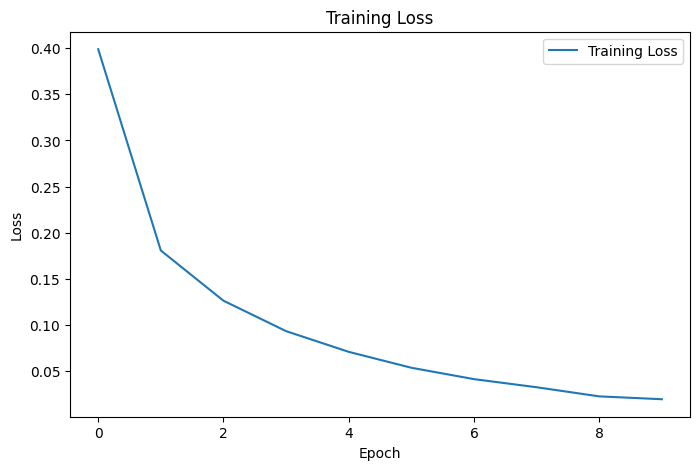

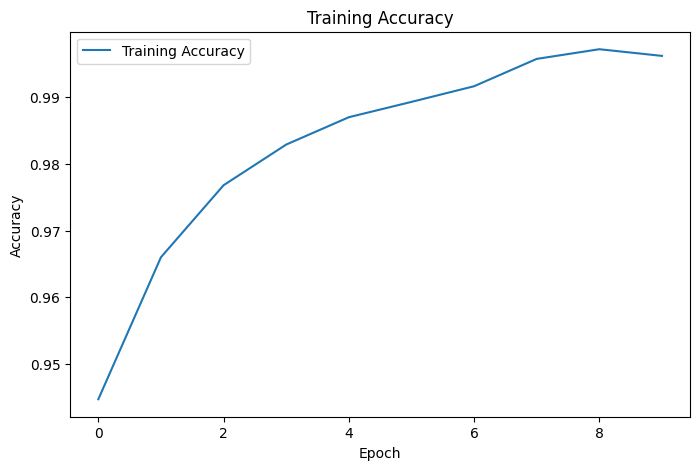

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history["accuracy"], label="Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()

In [ ]:
optimizers = ["sgd", "momentum", "rmsprop", "adam"]
optimizer_results = {}

for opt in optimizers:
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=0.001 if opt != "sgd" else 0.1,
        activation="relu",
        optimizer=opt
    )

    temp_history = temp_model.train(
        X_train_small,
        y_train_small,
        epochs=5,
        batch_size=32
    )

    optimizer_results[opt] = temp_model.accuracy(X_test, y_test)

optimizer_results

Epoch 1/5 - Loss: 0.4466 - Accuracy: 0.9261
Epoch 2/5 - Loss: 0.2390 - Accuracy: 0.9501
Epoch 3/5 - Loss: 0.1759 - Accuracy: 0.9635
Epoch 4/5 - Loss: 0.1390 - Accuracy: 0.9712
Epoch 5/5 - Loss: 0.1124 - Accuracy: 0.9750
Epoch 1/5 - Loss: 2.0787 - Accuracy: 0.5232
Epoch 2/5 - Loss: 1.6406 - Accuracy: 0.6735
Epoch 3/5 - Loss: 1.3235 - Accuracy: 0.7459
Epoch 4/5 - Loss: 1.0955 - Accuracy: 0.7827
Epoch 5/5 - Loss: 0.9349 - Accuracy: 0.8080
Epoch 1/5 - Loss: 0.3823 - Accuracy: 0.9423
Epoch 2/5 - Loss: 0.1903 - Accuracy: 0.9597
Epoch 3/5 - Loss: 0.1351 - Accuracy: 0.9701
Epoch 4/5 - Loss: 0.1026 - Accuracy: 0.9786
Epoch 5/5 - Loss: 0.0808 - Accuracy: 0.9815
Epoch 1/5 - Loss: 0.4053 - Accuracy: 0.9386
Epoch 2/5 - Loss: 0.1862 - Accuracy: 0.9632
Epoch 3/5 - Loss: 0.1329 - Accuracy: 0.9757
Epoch 4/5 - Loss: 0.0971 - Accuracy: 0.9799
Epoch 5/5 - Loss: 0.0732 - Accuracy: 0.9853


{'sgd': np.float64(0.956),
 'momentum': np.float64(0.81),
 'rmsprop': np.float64(0.9606),
 'adam': np.float64(0.9626)}

In [ ]:
learning_rates = [0.0001, 0.001, 0.01]
learning_rate_results = {}

for lr in learning_rates:
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=lr,
        activation="relu",
        optimizer="adam"
    )

    temp_model.train(
        X_train_small,
        y_train_small,
        epochs=5,
        batch_size=32
    )

    learning_rate_results[lr] = temp_model.accuracy(X_test, y_test)

learning_rate_results

Epoch 1/5 - Loss: 1.0214 - Accuracy: 0.8762
Epoch 2/5 - Loss: 0.4359 - Accuracy: 0.9039
Epoch 3/5 - Loss: 0.3432 - Accuracy: 0.9153
Epoch 4/5 - Loss: 0.2987 - Accuracy: 0.9241
Epoch 5/5 - Loss: 0.2687 - Accuracy: 0.9308
Epoch 1/5 - Loss: 0.3991 - Accuracy: 0.9415
Epoch 2/5 - Loss: 0.1819 - Accuracy: 0.9589
Epoch 3/5 - Loss: 0.1259 - Accuracy: 0.9757
Epoch 4/5 - Loss: 0.0935 - Accuracy: 0.9804
Epoch 5/5 - Loss: 0.0701 - Accuracy: 0.9879
Epoch 1/5 - Loss: 0.3098 - Accuracy: 0.9480
Epoch 2/5 - Loss: 0.1838 - Accuracy: 0.9607
Epoch 3/5 - Loss: 0.1294 - Accuracy: 0.9655
Epoch 4/5 - Loss: 0.1215 - Accuracy: 0.9705
Epoch 5/5 - Loss: 0.1156 - Accuracy: 0.9646


{0.0001: np.float64(0.927),
 0.001: np.float64(0.9643),
 0.01: np.float64(0.9366)}

In [ ]:
batch_sizes = [16, 32, 64, 128]
batch_results = {}

for batch in batch_sizes:
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=0.001,
        activation="relu",
        optimizer="adam"
    )

    temp_model.train(
        X_train_small,
        y_train_small,
        epochs=5,
        batch_size=batch
    )

    batch_results[batch] = temp_model.accuracy(X_test, y_test)

batch_results

Epoch 1/5 - Loss: 0.3468 - Accuracy: 0.9543
Epoch 2/5 - Loss: 0.1632 - Accuracy: 0.9718
Epoch 3/5 - Loss: 0.1105 - Accuracy: 0.9748
Epoch 4/5 - Loss: 0.0789 - Accuracy: 0.9868
Epoch 5/5 - Loss: 0.0576 - Accuracy: 0.9878
Epoch 1/5 - Loss: 0.3943 - Accuracy: 0.9417
Epoch 2/5 - Loss: 0.1877 - Accuracy: 0.9537
Epoch 3/5 - Loss: 0.1314 - Accuracy: 0.9727
Epoch 4/5 - Loss: 0.0984 - Accuracy: 0.9757
Epoch 5/5 - Loss: 0.0736 - Accuracy: 0.9866
Epoch 1/5 - Loss: 0.4744 - Accuracy: 0.9310
Epoch 2/5 - Loss: 0.2242 - Accuracy: 0.9523
Epoch 3/5 - Loss: 0.1676 - Accuracy: 0.9648
Epoch 4/5 - Loss: 0.1274 - Accuracy: 0.9728
Epoch 5/5 - Loss: 0.1021 - Accuracy: 0.9776
Epoch 1/5 - Loss: 0.5655 - Accuracy: 0.9149
Epoch 2/5 - Loss: 0.2649 - Accuracy: 0.9422
Epoch 3/5 - Loss: 0.2068 - Accuracy: 0.9534
Epoch 4/5 - Loss: 0.1686 - Accuracy: 0.9622
Epoch 5/5 - Loss: 0.1420 - Accuracy: 0.9687


{16: np.float64(0.9624),
 32: np.float64(0.9644),
 64: np.float64(0.9577),
 128: np.float64(0.9528)}

In [ ]:
hidden_sizes = [64, 128, 256]
hidden_results = {}

for hidden in hidden_sizes:
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=hidden,
        output_size=10,
        learning_rate=0.001,
        activation="relu",
        optimizer="adam"
    )

    temp_model.train(
        X_train_small,
        y_train_small,
        epochs=5,
        batch_size=32
    )

    hidden_results[hidden] = temp_model.accuracy(X_test, y_test)

hidden_results

Epoch 1/5 - Loss: 0.4518 - Accuracy: 0.9263
Epoch 2/5 - Loss: 0.2243 - Accuracy: 0.9504
Epoch 3/5 - Loss: 0.1668 - Accuracy: 0.9594
Epoch 4/5 - Loss: 0.1341 - Accuracy: 0.9714
Epoch 5/5 - Loss: 0.1077 - Accuracy: 0.9794
Epoch 1/5 - Loss: 0.3998 - Accuracy: 0.9400
Epoch 2/5 - Loss: 0.1899 - Accuracy: 0.9657
Epoch 3/5 - Loss: 0.1293 - Accuracy: 0.9742
Epoch 4/5 - Loss: 0.0972 - Accuracy: 0.9826
Epoch 5/5 - Loss: 0.0713 - Accuracy: 0.9861
Epoch 1/5 - Loss: 0.3522 - Accuracy: 0.9553
Epoch 2/5 - Loss: 0.1549 - Accuracy: 0.9674
Epoch 3/5 - Loss: 0.1012 - Accuracy: 0.9842
Epoch 4/5 - Loss: 0.0689 - Accuracy: 0.9832
Epoch 5/5 - Loss: 0.0499 - Accuracy: 0.9890


{64: np.float64(0.959), 128: np.float64(0.9617), 256: np.float64(0.9633)}

In [ ]:
activations = ["relu", "sigmoid"]
activation_results = {}

for act in activations:
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=0.001,
        activation=act,
        optimizer="adam"
    )

    temp_model.train(
        X_train_small,
        y_train_small,
        epochs=5,
        batch_size=32
    )

    activation_results[act] = temp_model.accuracy(X_test, y_test)

activation_results

Epoch 1/5 - Loss: 0.4045 - Accuracy: 0.9385
Epoch 2/5 - Loss: 0.1869 - Accuracy: 0.9643
Epoch 3/5 - Loss: 0.1300 - Accuracy: 0.9757
Epoch 4/5 - Loss: 0.0937 - Accuracy: 0.9802
Epoch 5/5 - Loss: 0.0741 - Accuracy: 0.9861
Epoch 1/5 - Loss: 0.6387 - Accuracy: 0.9091
Epoch 2/5 - Loss: 0.2960 - Accuracy: 0.9322
Epoch 3/5 - Loss: 0.2349 - Accuracy: 0.9441
Epoch 4/5 - Loss: 0.1950 - Accuracy: 0.9516
Epoch 5/5 - Loss: 0.1658 - Accuracy: 0.9624


{'relu': np.float64(0.9608), 'sigmoid': np.float64(0.945)}

In [ ]:
batch_types = {
    "Stochastic": 1,
    "Mini-Batch": 32,
    "Batch": len(X_train_small)
}

batch_type_results = {}

for name, batch in batch_types.items():
    temp_model = NeuralNetwork(
        input_size=784,
        hidden_size=128,
        output_size=10,
        learning_rate=0.001,
        activation="relu",
        optimizer="adam"
    )

    temp_model.train(
        X_train_small,
        y_train_small,
        epochs=3,
        batch_size=batch
    )

    batch_type_results[name] = temp_model.accuracy(X_test, y_test)

batch_type_results

Epoch 1/3 - Loss: 0.2891 - Accuracy: 0.9670
Epoch 2/3 - Loss: 0.1396 - Accuracy: 0.9691
Epoch 3/3 - Loss: 0.1038 - Accuracy: 0.9821
Epoch 1/3 - Loss: 0.4023 - Accuracy: 0.9380
Epoch 2/3 - Loss: 0.1890 - Accuracy: 0.9589
Epoch 3/3 - Loss: 0.1306 - Accuracy: 0.9741
Epoch 1/3 - Loss: 2.4721 - Accuracy: 0.0781
Epoch 2/3 - Loss: 2.3027 - Accuracy: 0.1962
Epoch 3/3 - Loss: 2.1541 - Accuracy: 0.3630


{'Stochastic': np.float64(0.9625),
 'Mini-Batch': np.float64(0.9568),
 'Batch': np.float64(0.3579)}

In [ ]:
print("Single Layer Accuracy:", single_test_accuracy)
print("Multi Layer Accuracy:", test_accuracy)

print("\nOptimizer Results:")
for key, value in optimizer_results.items():
    print(key, ":", value)

print("\nLearning Rate Results:")
for key, value in learning_rate_results.items():
    print(key, ":", value)

print("\nBatch Size Results:")
for key, value in batch_results.items():
    print(key, ":", value)

print("\nHidden Neuron Results:")
for key, value in hidden_results.items():
    print(key, ":", value)

print("\nActivation Results:")
for key, value in activation_results.items():
    print(key, ":", value)

print("\nBatch Type Results:")
for key, value in batch_type_results.items():
    print(key, ":", value)

Single Layer Accuracy: 0.917
Multi Layer Accuracy: 0.9656

Optimizer Results:
sgd : 0.956
momentum : 0.81
rmsprop : 0.9606
adam : 0.9626

Learning Rate Results:
0.0001 : 0.927
0.001 : 0.9643
0.01 : 0.9366

Batch Size Results:
16 : 0.9624
32 : 0.9644
64 : 0.9577
128 : 0.9528

Hidden Neuron Results:
64 : 0.959
128 : 0.9617
256 : 0.9633

Activation Results:
relu : 0.9608
sigmoid : 0.945

Batch Type Results:
Stochastic : 0.9625
Mini-Batch : 0.9568
Batch : 0.3579


In [ ]:
sample_predictions = model.predict(X_test[:10])
actual_labels = np.argmax(y_test[:10], axis=1)

print("Predicted:", sample_predictions)
print("Actual   :", actual_labels)

Predicted: [7 2 1 0 4 1 4 9 6 9]
Actual   : [7 2 1 0 4 1 4 9 5 9]
